# La France est-elle en retard en IA, ou simplement plus transparente ?

*Projet Python pour la data science, ENSAE 2A (2026-2027)*

Ce notebook est notre rapport final. Il s'exécute de bout en bout, de la collecte des données aux conclusions. Les analyses complémentaires (tests de robustesse, graphiques supplémentaires) sont dans le dossier `notebooks/`.

## Introduction

On entend souvent que la France est en retard en intelligence artificielle. Elle a pourtant Mistral AI, l'un des seuls développeurs européens de grands modèles de langage, et 18 % des entreprises de 10 salariés ou plus implantées en France utilisaient au moins une technologie d'IA en 2025 ([Insee](https://www.insee.fr/fr/statistiques/9025878)). Depuis le 2 août 2025, l'AI Act impose aussi des obligations aux développeurs de modèles d'IA à usage général, avec un code de bonnes pratiques que chacun peut signer.

Mais pour mesurer un retard, il faut connaître les modèles des leaders, et ceux-ci publient de moins en moins d'informations. On se pose donc trois questions. À quelle étape la France décroche-t-elle : la recherche, les modèles ou leur diffusion ? Le manque de transparence des leaders fausse-t-il la comparaison ? Enfin, nous nous demandons de quoi parle la recherche française en IA, et si ses thèmes expliquent en partie pourquoi elle produit peu de modèles.

## Démarche

On compare la France à cinq pays (États-Unis, Chine, Royaume-Uni, Allemagne, Canada) à trois étapes : la recherche, les modèles et leur diffusion. On regarde ensuite si les développeurs publient de moins en moins d'informations sur leurs modèles, et si cela change la mesure du retard. Enfin, nous analysons les résumés des articles d'IA les plus cités en France et aux États-Unis, avec les méthodes de traitement du texte vues en cours (spaCy, TF-IDF, nuages de mots) et avec des embeddings, pour comparer les thèmes de recherche des deux pays.

Avant de regarder les données, on a posé six hypothèses :

- **H1** : la France publie beaucoup en IA mais produit peu de modèles.
- **H2** : sa présence parmi les modèles repose sur très peu d'acteurs.
- **H3** : les développeurs publient de moins en moins d'informations sur leurs modèles depuis 2020.
- **H4** : les modèles dont les poids sont publiés (modèles ouverts) sont mieux documentés que les modèles fermés.
- **H5** : les signataires du code de bonnes pratiques de l'AI Act sont devenus plus transparents.
- **H6** : la recherche française en IA est plus théorique, tournée vers l'explicabilité et les statistiques, alors que la recherche américaine se concentre sur les grands modèles de langage.

## 1. Les données

### Collecte

Nous avons utilisé six sources, toutes collectées par un script du dossier `src/`. La principale est Epoch AI, qui recense les modèles d'IA notables. Nous nous sommes aussi servis de l'index de transparence de Stanford. Ces deux sources sont des fichiers CSV. Les publications scientifiques en IA viennent de l'API d'OpenAlex, les téléchargements des modèles ouverts de l'API de Hugging Face et la population et le PIB de chaque pays de l'API de la Banque mondiale. Pour finir, nous avons récupéré par web scraping, sur le site de la Commission européenne, la liste des signataires du code de bonnes pratiques de l'AI Act.

Chaque script enregistre une copie datée dans `data/raw/` et une copie au format Parquet est aussi ajoutée sur le stockage MinIO du SSP Cloud. Comme les sources sont mises à jour régulièrement, le rapport relit par défaut les copies datées versionnées dans `data/raw/` (collecte du 22 novembre 2026, et du 24 novembre pour Hugging Face), afin d'obtenir les mêmes résultats à chaque fois, avec ou sans accès au SSP Cloud. Pour tout re-télécharger, il suffit de passer la variable `COLLECTER` à `True`. La collecte prend quelques minutes et une clé OpenAlex gratuite, placée dans la variable d'environnement `OPENALEX_API_KEY`, permet de ne pas être limité par l'API.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd() / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import spacy

import geopandas as gpd

from config import FIGURES, FOND_MONDE
from style import COULEURS_PAYS, appliquer_style
from nettoyage import (charger_dernier, preparer_epoch, eclater_pays,
                       annees_de_retard, INFOS_PUBLIABLES)
from texte import corpus_resumes, nettoyer, comparer_presence, tfidf_par_groupe, nuage
from graphiques import (courbes_par_pays, profil_maillons, barres_rapport,
                        barres_par_pays, nuage_de_points_annote, carte_monde)
import analyses

appliquer_style()
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.precision", 2)

In [2]:
COLLECTER = False

if COLLECTER:
    from pipeline import collecter_tout
    collecter_tout()

In [3]:
epoch = preparer_epoch(charger_dernier("epoch_notable_models"))
epoch_pays = eclater_pays(epoch)
publications = charger_dernier("openalex_publications")
resumes = charger_dernier("openalex_resumes")
hf = charger_dernier("hf_models")
fmti = charger_dernier("fmti_scores")
signataires = charger_dernier("signataires_code")
pays_info = charger_dernier("banque_mondiale")


def periode(annees):
    """Première et dernière année d'une colonne, sous la forme « 2015-2025 »."""
    return f"{annees.min()}-{annees.max()}"


annees_hf = hf["createdAt"].str[:4]   # les 4 premiers caractères de la date = l'année
resume_sources = {
    "Epoch AI": [len(epoch), "modèles", periode(epoch["annee"])],
    "OpenAlex (comptages)": [len(publications), "pays × années", periode(publications["annee"])],
    "OpenAlex (résumés)": [len(resumes), "résumés d'articles", periode(resumes["annee"])],
    "Hugging Face": [len(hf), "modèles", periode(annees_hf)],
    "Stanford FMTI": [fmti["developpeur"].nunique(), "développeurs notés", ", ".join(sorted(fmti["edition"].unique()))],
    "Code européen": [len(signataires), "signataires", "liste à date"],
    "Banque mondiale": [len(pays_info), "pays × années", periode(pays_info["annee"])],
}
pd.DataFrame.from_dict(resume_sources, orient="index", columns=["lignes", "unité", "période"])

Lecture locale : data/raw/epoch_notable_models_2026-11-22.csv
Lecture locale : data/raw/openalex_publications_2026-11-22.csv
Lecture locale : data/raw/openalex_resumes_2026-11-22.csv
Lecture locale : data/raw/hf_models_2026-11-24.csv
Lecture locale : data/raw/fmti_scores_2026-11-22.csv
Lecture locale : data/raw/signataires_code_2026-11-22.csv
Lecture locale : data/raw/banque_mondiale_2026-11-22.csv


,lignes,unité,période
Epoch AI,1102,modèles,1950-2026
OpenAlex (comptages),66,pays × années,2015-2025
OpenAlex (résumés),2000,résumés d'articles,2022-2026
Hugging Face,3887,modèles,2022-2026
Stanford FMTI,22,développeurs notés,"2023-10, 2024-05, 2025-12"
Code européen,23,signataires,liste à date
Banque mondiale,66,pays × années,2015-2025


### Choix de nettoyage

Les choix de nettoyage qui suivent servent nos deux premières questions (ceux de la troisième, sur les textes, sont décrits en partie 4). La France est-elle en retard en IA ? Et le fait que les grands développeurs publient de moins en moins d'informations fausse-t-il cette comparaison ? Les données brutes ne permettent pas d'y répondre directement.

Pour mesurer le retard de la France, il faut d'abord compter combien de modèles chaque pays a développés. La difficulté est que certains modèles sont le fruit d'une collaboration entre plusieurs pays. Si on les comptait en entier pour chacun d'eux, un même modèle serait compté plusieurs fois et les pays qui collaborent beaucoup paraîtraient plus productifs qu'ils ne le sont. Nous avons donc partagé chaque modèle à parts égales entre les organisations qui l'ont développé, chaque part allant au pays de l'organisation. Ainsi, un modèle conçu par une entreprise américaine et un laboratoire français compte pour moitié aux États-Unis et pour moitié en France, et un modèle conçu par deux organisations américaines et une française compte pour deux tiers aux États-Unis et un tiers en France. C'est ce qu'on appelle le comptage fractionnaire.

La seconde question porte sur la transparence. Pour comparer la France aux leaders, il faut connaître les caractéristiques de leurs modèles, en particulier leur puissance de calcul, qui indique à quel point un modèle est avancé. Si ces informations manquent, on ne peut pas savoir précisément où en sont les leaders, ni donc mesurer correctement le retard de la France. Pour chaque modèle, nous avons donc relevé si cinq informations étaient connues, à savoir la puissance de calcul, le nombre de paramètres, la taille des données d'entraînement, le coût et le matériel utilisé. Cela nous permet de voir si les développeurs publient de moins en moins, et lesquels.

Pour comprendre pourquoi certains développeurs publient moins que d'autres, nous avons aussi distingué les modèles ouverts, que tout le monde peut télécharger comme ceux de Mistral, des modèles fermés, qu'on ne peut utiliser qu'en ligne comme ChatGPT. Un développeur qui garde son modèle fermé le fait souvent pour des raisons commerciales, et on peut s'attendre à ce qu'il cache aussi davantage d'informations sur la manière dont il l'a construit. Lorsque Epoch ne précise pas si un modèle est ouvert, nous avons laissé l'information vide plutôt que de le supposer fermé.

Enfin, quelques corrections rendent les données plus fiables. Nous avons inclus les articles publiés en conférence, principal lieu de publication de la recherche en IA, pour ne pas sous-estimer la recherche française. Nous avons fait correspondre les noms d'entreprises qui varient d'une base à l'autre, comme « Google » et « Google DeepMind », afin de pouvoir croiser les différentes sources. Nous avons aussi retiré les articles d'informatique quantique, qu'OpenAlex classe à tort dans l'intelligence artificielle.

Le taux de remplissage de chaque variable et les contrôles faits au chargement sont dans l'annexe `notebooks/01_epoch_descriptif.ipynb` (section 0), et le code du nettoyage dans `src/nettoyage.py`. L'annexe 01 prolonge les parties 2 et 3, l'annexe 03 la partie 2, l'annexe 04 la partie 3 et l'annexe 02 la partie 4.

## 2. Où la France décroche-t-elle ?

### 2.0 Où sont produits les modèles d'IA ?

Nombre de modèles notables par pays depuis 1950 (comptage fractionnaire). La carte utilise la projection Equal Earth, qui respecte les surfaces, et les classes sont choisies à la main. Le fond de carte (Natural Earth, domaine public) est versionné dans `data/fond_carte/`.

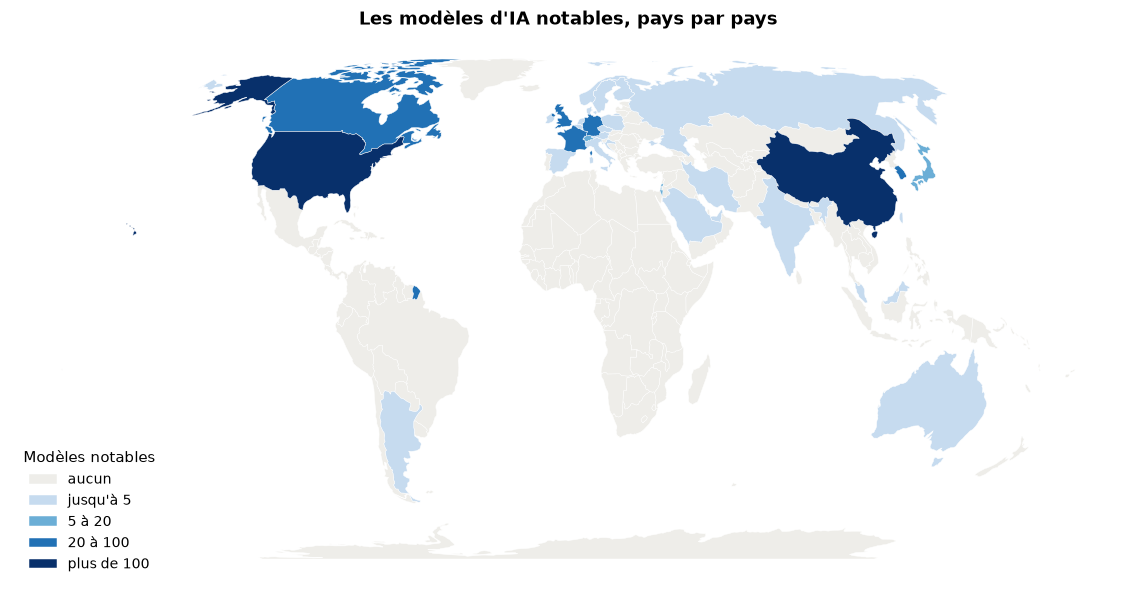

Absents de la carte (territoires trop petits à cette échelle, ou non localisés) : {'Hong Kong': 9.1, 'Inconnu': 20.0, 'Multinational': 3.5, 'Singapore': 8.6}


,ADMIN,modeles
4,United States of America,643.9
139,China,169.3
143,United Kingdom,72.5
3,Canada,42.8
43,France,28.7
96,South Korea,24.8
121,Germany,21.5
127,Switzerland,10.3
155,Japan,10.0
76,Israel,6.6


In [4]:
fond = gpd.read_file(FOND_MONDE)[["ADMIN", "geometry"]]
carte, absents = analyses.modeles_par_pays_monde(epoch_pays, fond)
carte_monde(carte, "modeles", "Les modèles d'IA notables, pays par pays",
            fichier=FIGURES / "rapport_0_carte.png")
plt.show()
print("Absents de la carte (territoires trop petits à cette échelle, ou non localisés) :",
      absents.round(1).to_dict())
carte.sort_values("modeles", ascending=False)[["ADMIN", "modeles"]].head(10).round(1)

**Interprétation.** Avant d'approfondir la recherche sur la France, nous avons souhaité situer les grands producteurs de modèles d'IA dans le monde. De manière peu surprenante, les États-Unis dominent largement, avec 644 modèles notables. La Chine se trouve en seconde place avec 169. Viennent ensuite le Royaume-Uni avec 72 modèles, le Canada avec 43, la France avec 29, la Corée du Sud avec 25 et l'Allemagne avec 21. La France est donc l'un des leaders européens, mais produit cependant 22 fois moins de modèles que les États-Unis. Le reste du monde, en particulier l'Afrique et l'Amérique latine, n'en produit presque aucun. Hong Kong et Singapour en produisent chacun 9, mais sont trop petits pour apparaître sur la carte.

### 2.1 La France à chaque étape

Part de chaque pays parmi les six comparés, sur 2024-2025 : articles d'IA, articles dans le 1 % les plus cités, modèles notables, modèles de pointe et téléchargements sur Hugging Face. Les téléchargements font exception pour la période : ce sont ceux relevés le 24 novembre 2026 pour les modèles de 14 organisations suivies (liste dans `src/collecte_huggingface.py`), quelle que soit leur date de création.

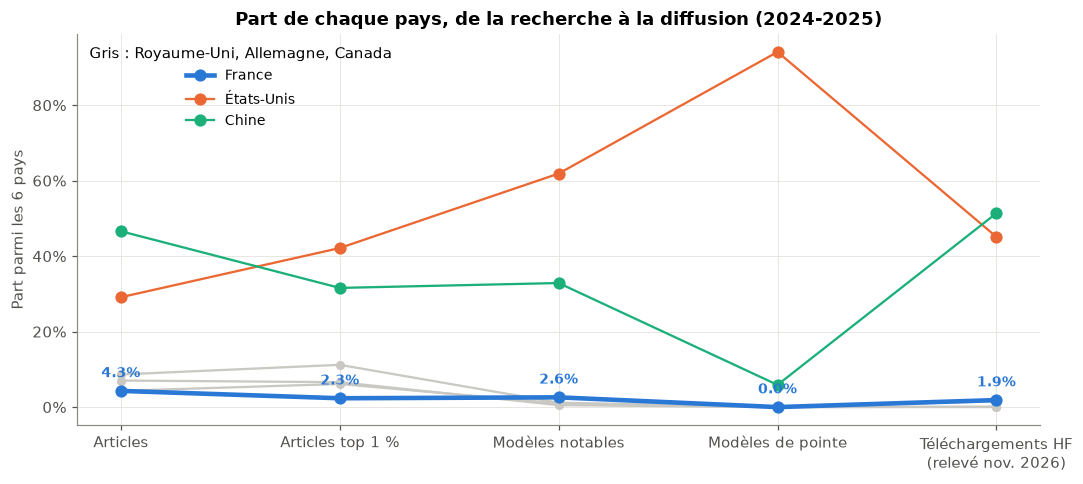

,Articles,Articles top 1 %,Modèles notables,Modèles de pointe,Téléchargements HF (relevé nov. 2026)
pays,,,,,
France,4.3%,2.3%,2.6%,0.0%,1.9%
États-Unis,29.1%,42.1%,61.9%,94.1%,45.1%
Chine,46.6%,31.6%,32.9%,5.9%,51.4%
Royaume-Uni,8.6%,11.2%,1.2%,0.0%,1.5%
Allemagne,7.0%,6.6%,0.5%,0.0%,0.0%
Canada,4.3%,6.1%,1.0%,0.0%,0.1%


In [5]:
chaine = analyses.chaine_par_periode(publications, epoch_pays)
profil = analyses.profil_recent(chaine, hf)
profil_maillons(profil, "Part de chaque pays, de la recherche à la diffusion (2024-2025)",
                fichier=FIGURES / "rapport_1_profil.png")
plt.show()
profil.style.format("{:.1%}")

In [6]:
# Articles d'IA pour un million d'habitants, cumul 2022-2024 (chiffres cités dans l'interprétation)
recent = publications.merge(pays_info, on=["pays", "annee"]).query("2022 <= annee <= 2024")
(recent.groupby("pays")["publications"].sum() / recent.groupby("pays")["population"].mean() * 1e6).round(0).sort_values()

pays
Chine           70.0
France         171.0
États-Unis     188.0
Allemagne      190.0
Canada         254.0
Royaume-Uni    277.0
dtype: float64

**Interprétation.** Nous avons essayé d'identifier à quel moment la France décroche. Pour cela, nous suivons la place de la France à chaque étape, de la recherche jusqu'à l'utilisation des modèles, en la comparant à cinq autres pays, les États-Unis, la Chine, le Royaume-Uni, l'Allemagne et le Canada. Notre hypothèse était qu'elle publie beaucoup mais produit peu de modèles, et le graphique la confirme. Sur 2024 et 2025, la France représente 4,3 % des articles d'IA publiés par ces six pays, mais seulement 2,3 % des articles les plus cités : c'est le recul le plus marqué des six pays entre ces deux étapes. Sa part reste ensuite à 2,6 % des modèles notables (5 modèles), puis tombe à 0 % des modèles de pointe, dont les États-Unis concentrent 94 %. L'Allemagne et le Canada reculent d'ailleurs bien plus que la France entre les articles et les modèles (de 7,0 % à 0,5 % et de 4,3 % à 1,0 %).

Néanmoins, il faut prendre en compte le fait que la France est beaucoup moins peuplée que les États-Unis ou la Chine. Une fois rapportée à sa population, la France publie presque autant d'articles scientifiques en IA que les États-Unis, avec 171 articles par million d'habitants entre 2022 et 2024, contre 188, et un peu moins que l'Allemagne avec 190. Le Royaume-Uni et le Canada font mieux, avec respectivement 277 et 254 articles. Nous pouvons donc penser que la France ne manque pas de recherche en volume, mais qu'elle décroche à deux endroits : parmi les articles les plus cités, puis au moment de produire des modèles de pointe.

Les téléchargements vont dans le même sens. Les modèles français ne représentent que 1,9 % des téléchargements des 14 organisations suivies sur Hugging Face. La Chine, avec 51 % des téléchargements, y dépasse désormais les États-Unis, qui en ont 45 %, grâce au succès de ses modèles ouverts comme ceux de DeepSeek ou d'Alibaba. L'Allemagne et le Canada sont presque absents de la plateforme, avec moins de 0,2 % des téléchargements à eux deux.

### 2.2 De la recherche aux modèles

Nombre de modèles notables pour 1 000 articles d'IA, par période.

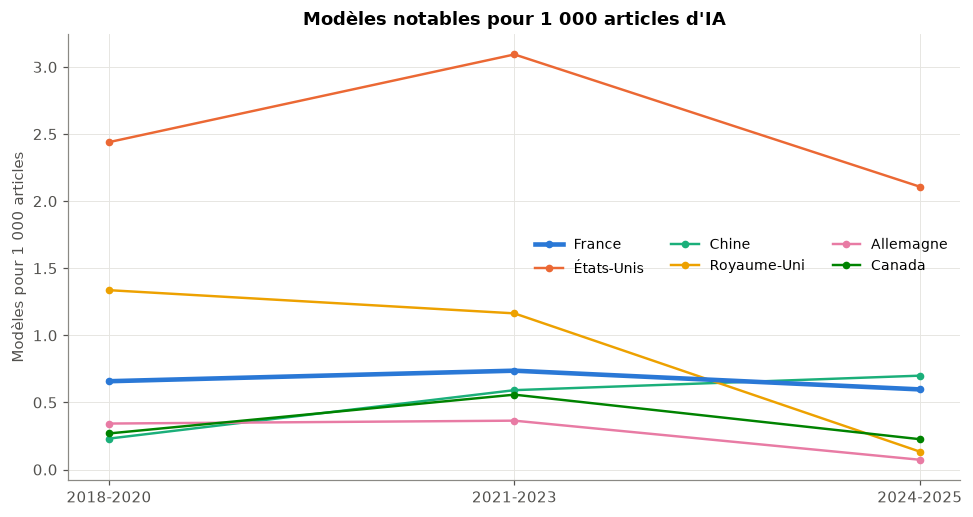

periode,2018-2020,2021-2023,2024-2025
pays,,,
France,0.66,0.74,0.60
États-Unis,2.44,3.09,2.11
Chine,0.23,0.59,0.70
Royaume-Uni,1.34,1.16,0.13
Allemagne,0.34,0.36,0.07
Canada,0.27,0.56,0.23


In [7]:
transformation = chaine.pivot(index="pays", columns="periode", values="modeles_pour_1000_articles").reindex(analyses.PAYS)
courbes_par_pays(transformation.T, "Modèles notables pour 1 000 articles d'IA",
                 "Modèles pour 1 000 articles", fichier=FIGURES / "rapport_1b_transformation.png")
plt.show()
transformation.round(2)

**Interprétation.** Pour mesurer l'écart entre la recherche et les modèles, nous avons calculé combien de modèles notables chaque pays produit pour 1 000 articles d'IA publiés. Sur les années 2024 et 2025, la France en a produit 0,6 contre 2,1 aux États-Unis, soit trois fois et demie moins. Elle fait en revanche mieux que l'Allemagne (0,07) et le Canada (0,23). Ce chiffre n'a presque pas bougé depuis 2018, puisqu'il était de 0,66 entre 2018 et 2020 puis de 0,74 entre 2021 et 2023. La Chine, au contraire, l'a multiplié par trois, passant de 0,23 à 0,70, et transforme donc de mieux en mieux sa recherche en modèles.

En revanche, le Royaume-Uni est passé de 1,34 à 0,13. Mais cet effet semble provenir de la base de données. Depuis la fusion de DeepMind avec Google Brain en 2023, Epoch AI attribue les modèles de Google DeepMind aux États-Unis, bien qu'une partie des équipes travaille à Londres. Il faut enfin garder en tête que ces chiffres servent surtout à comparer les pays entre eux et dans le temps. Les articles sont comptés en entier alors que les modèles sont partagés entre pays, et la valeur exacte du ratio a donc peu de sens à elle seule.

### 2.3 Une présence qui tient à peu d'acteurs

Modèles français depuis 2024 : 7.0, dont Mistral AI : 7.0


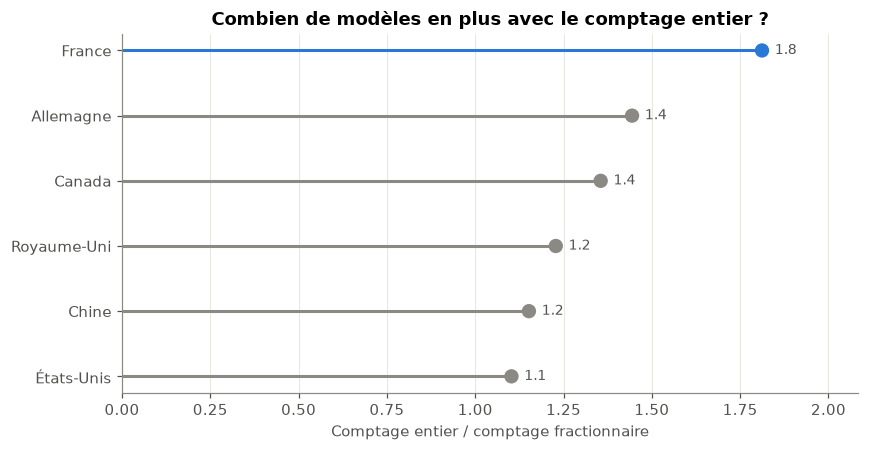

Organization
Mistral AI                    8.00
Facebook AI Research          5.50
INRIA                         2.00
Facebook AI Research,INRIA    1.33
Hugging Face,BigScience       1.00
Name: poids, dtype: float64

,fractionnaire,entier,entier / fractionnaire
pays,,,
France,28.70,52.0,1.81
États-Unis,643.92,710.0,1.10
Chine,169.27,195.0,1.15
Royaume-Uni,72.47,89.0,1.23
Allemagne,21.47,31.0,1.44
Canada,42.80,58.0,1.36


In [8]:
fr = epoch_pays.loc[epoch_pays["pays"] == "France"]
par_organisation = fr.groupby("Organization")["poids"].sum().sort_values(ascending=False)

depuis_2024 = fr.loc[fr["annee"] >= 2024]
est_mistral = depuis_2024["Organization"].str.contains("Mistral", na=False)
print(f"Modèles français depuis 2024 : {depuis_2024['poids'].sum():.1f}, "
      f"dont Mistral AI : {depuis_2024.loc[est_mistral, 'poids'].sum():.1f}")

comptages = pd.DataFrame({
    "fractionnaire": epoch_pays.groupby("pays")["poids"].sum(),
    "entier": eclater_pays(epoch, "entier").groupby("pays")["poids"].sum(),
}).reindex(analyses.PAYS)
comptages["entier / fractionnaire"] = comptages["entier"] / comptages["fractionnaire"]
barres_par_pays(comptages["entier / fractionnaire"], "Combien de modèles en plus avec le comptage entier ?",
                "Comptage entier / comptage fractionnaire", pourcentage=False,
                fichier=FIGURES / "rapport_1c_comptages.png")
plt.show()
display(par_organisation.head(5).round(2))
comptages.round(2)

**Interprétation.** Notre deuxième hypothèse était que la présence de la France parmi les modèles d'IA repose sur très peu d'acteurs, et c'est bien le cas. Depuis 2024, la France compte sept modèles notables, et ils ont tous été développés par Mistral AI. Si cette seule entreprise venait à ralentir ou à être rachetée, la France disparaîtrait presque des classements.

Nous avons aussi refait le décompte en comptage entier, c'est-à-dire en comptant chaque modèle en entier pour chacun des pays qui y ont participé. La France passe alors de 28,7 à 52 modèles, soit presque le double, alors que les États-Unis ne gagnent que 10 %. Une grande partie des modèles français sont donc des collaborations avec d'autres pays, souvent issues du laboratoire parisien de Facebook AI Research, qui appartient à l'entreprise américaine Meta. Ce choix de comptage change beaucoup le chiffre de la France, mais pas son rang parmi les six pays comparés, où elle reste cinquième derrière le Canada. Il confirme surtout que sa position dépend en partie d'acteurs étrangers.

### 2.4 Le retard en puissance de calcul

La puissance de calcul d'un modèle se mesure en FLOP, le nombre d'opérations faites pendant l'entraînement. On regarde d'abord le modèle le plus puissant de chaque année. Ensuite, pour chaque pays, on cherche en quelle année les États-Unis avaient déjà atteint son record : l'écart donne un retard en années. Une année sans point sur le graphique est une année où aucun modèle du pays n'a de puissance de calcul connue (2024 et 2025 pour la France).

,record (FLOP),× par rapport à l'année précédente
annee,,
2018,8.7e+21,10.4
2019,1.1e+23,12.3
2020,3.1e+23,2.9
2021,2.0e+24,6.5
2022,2.7e+24,1.3
2023,5.0e+25,18.2
2024,3.8e+25,0.8
2025,5.0e+26,13.2
2026,9.4e+26,1.9


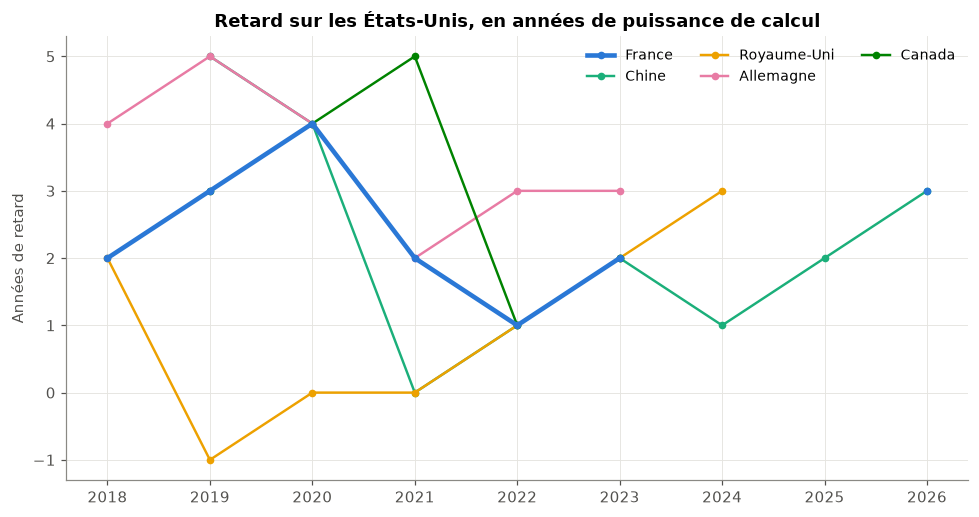

In [9]:
record = analyses.record_par_annee(epoch)
display(record.loc[record.index >= 2018].style.format({"record (FLOP)": "{:.1e}", "× par rapport à l'année précédente": "{:.1f}"}))
retard = annees_de_retard(epoch_pays).pivot(index="annee", columns="pays", values="retard_annees")
retard = retard.loc[retard.index >= 2018, [p for p in analyses.PAYS if p != "États-Unis"]]
courbes_par_pays(retard, "Retard sur les États-Unis, en années de puissance de calcul",
                 "Années de retard", fichier=FIGURES / "rapport_2_retard.png")
plt.show()

**Interprétation.** La puissance de calcul utilisée pour entraîner un modèle est un indicateur courant de son niveau, car les modèles les plus performants sont en général ceux qui demandent le plus de calcul. Elle ne mesure pas directement leurs performances. Elle se mesure en FLOP, c'est-à-dire en nombre d'opérations effectuées pendant l'entraînement. Le record mondial a été multiplié par environ 100 000 entre 2018 et 2026, passant de 8,7 × 10²¹ à 9,4 × 10²⁶ FLOP, et il a même été multiplié par 18 en une seule année, en 2023. La course se joue donc sur des écarts énormes, et quelques années de retard représentent une différence considérable.

Pour traduire cet écart en années, nous avons cherché, pour chaque année, à quelle date les États-Unis avaient déjà atteint le record français. Depuis 2018, la France a entre un et quatre ans de retard. En 2026, son modèle le plus puissant correspond au niveau que les États-Unis avaient atteint en 2023, soit trois ans de retard, et cet écart ne se réduit pas. Ce calcul a cependant deux limites. Il ne porte que sur les modèles dont la puissance de calcul est connue, et un seul nouveau modèle français suffit à faire varier le retard d'une année.

## 3. Les développeurs publient-ils de moins en moins ?

### 3.1 Des informations qui disparaissent

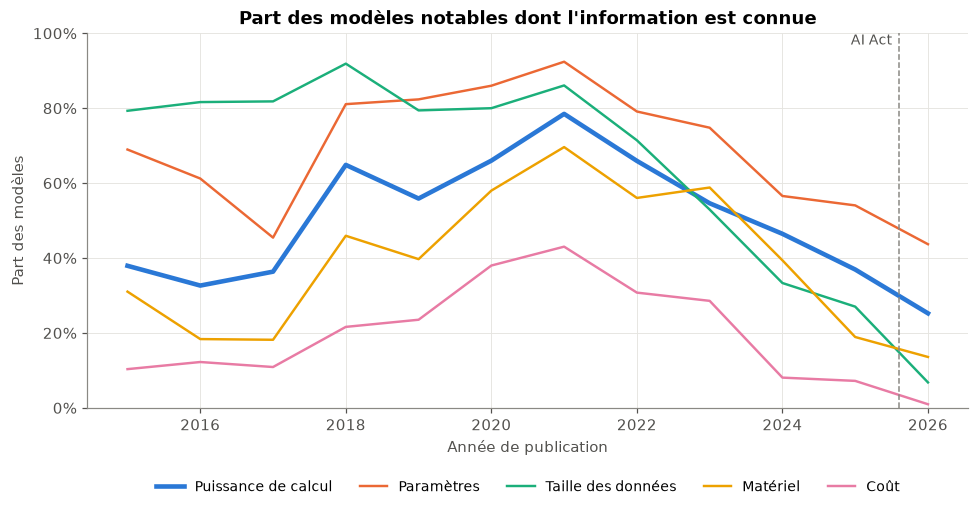

,publie_calcul,publie_parametres,publie_donnees,publie_cout,publie_materiel
annee,,,,,
2018,65%,81%,92%,22%,46%
2021,78%,92%,86%,43%,70%
2024,46%,57%,33%,8%,39%
2025,37%,54%,27%,7%,19%
2026,25%,44%,7%,1%,14%


In [10]:
evolution = epoch.loc[epoch["annee"] >= 2015].groupby("annee")[list(INFOS_PUBLIABLES.values())].mean()
noms = {"publie_calcul": "Puissance de calcul", "publie_parametres": "Paramètres",
        "publie_donnees": "Taille des données", "publie_materiel": "Matériel", "publie_cout": "Coût"}
fig, ax = plt.subplots()
for (col, nom), c in zip(noms.items(), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]):
    ax.plot(evolution.index, evolution[col], color=c, label=nom, linewidth=3 if col == "publie_calcul" else 1.6)
ax.axvline(2025.6, color="#8a8984", linestyle="--", linewidth=1)
ax.text(2025.5, 0.97, "AI Act", ha="right", fontsize=9, color="#52514e")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 1)
ax.set_title("Part des modèles notables dont l'information est connue")
ax.set_xlabel("Année de publication"); ax.set_ylabel("Part des modèles")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES / "rapport_3_opacite.png"); plt.show()
evolution.loc[[2018, 2021, 2024, 2025, 2026]].style.format("{:.0%}")

**Interprétation.** L'hypothèse H3, selon laquelle les développeurs publient de moins en moins d'informations sur leurs modèles, est confirmée. La part des modèles dont la puissance de calcul est connue atteint 78 % en 2021, puis tombe à 46 % en 2024 et 25 % en 2026. La taille des données d'entraînement suit la même tendance, et le coût n'est presque jamais connu (1 % en 2026). La baisse commence après 2021, quand les grands modèles deviennent des produits commerciaux. Pour les deux dernières années, une partie de la baisse vient aussi du fait qu'Epoch complète ses fiches avec du retard. Les effets de l'AI Act sur cette tendance ne peuvent pas encore être observés, car les dernières données sont trop proches de la date d'entrée en application de la loi, ce qui rend toute interprétation difficile.

### 3.2 Information publiée ou estimée ?

In [11]:
sources = (pd.crosstab(epoch.loc[epoch["annee"] >= 2018, "annee"],
                       epoch.loc[epoch["annee"] >= 2018, "source_calcul"], normalize="index")
           .reindex(columns=["calculée depuis des infos publiées", "estimation indirecte", "non renseignée"], fill_value=0))
sources.style.format("{:.0%}")

source_calcul,calculée depuis des infos publiées,estimation indirecte,non renseignée
annee,,,
2018,57%,8%,35%
2019,40%,16%,44%
2020,50%,16%,34%
2021,67%,11%,22%
2022,60%,5%,34%
2023,41%,13%,45%
2024,41%,5%,54%
2025,30%,7%,63%
2026,20%,5%,75%


**Interprétation.** La baisse ne semble pas venir de la méthode d'Epoch : les estimations indirectes restent rares (5 à 16 % des modèles selon les années depuis 2018). Ce qui baisse, c'est la part des modèles dont on peut calculer la puissance de calcul à partir de ce que publie le développeur : 67 % en 2021, 20 % en 2026. Cela confirme bien notre hypothèse selon laquelle l'information publiée directement par les développeurs s'amenuise au fur et à mesure du temps. L'estimation indirecte ne joue qu'un rôle annexe dans cela et sa part reste assez stable et minime au cours du temps.

### 3.3 Qui publie ?

Part des modèles dont la puissance de calcul est connue, par période, selon que les poids du modèle sont publiés (modèle ouvert, que tout le monde peut télécharger) ou non.

In [12]:
publication = analyses.tableau_publication(epoch)
publication.style.format({"fermé": "{:.0%}", "poids ouverts": "{:.0%}"})

acces,fermé,poids ouverts,"nombre, fermé","nombre, poids ouverts"
periode,,,,
2018-2020,64%,63%,80,68
2021-2023,55%,75%,147,141
2024-2026,18%,64%,191,122


**Interprétation.** Jusqu'en 2020, les modèles ouverts et fermés étaient aussi bien documentés (63 % et 64 %). Ensuite, la part des modèles fermés tombe à 55 % sur 2021-2023 puis à 18 % depuis 2024, alors que celle des modèles ouverts reste entre 64 % et 75 %. H4 est donc confirmée, mais seulement à partir de 2021. Chaque case compte plus de 120 modèles depuis 2021, donc ces écarts ne reposent pas sur quelques cas. Cela s'explique notamment par le fait que les développeurs de modèles ouverts cherchent à favoriser la transparence, la collaboration scientifique et l'adoption de leurs technologies. À l'inverse, les entreprises développant des modèles fermés limitent la divulgation d'informations techniques afin de protéger leur propriété intellectuelle, leur avantage concurrentiel et parfois la sécurité de leurs modèles.

### 3.4 Deux mesures de la transparence qui ne disent pas la même chose

Stanford note ce que chaque développeur publie, sur une centaine d'indicateurs. Epoch indique ce qui est connu de ses modèles. Si les deux mesuraient la même chose, les points du graphique monteraient de gauche à droite.

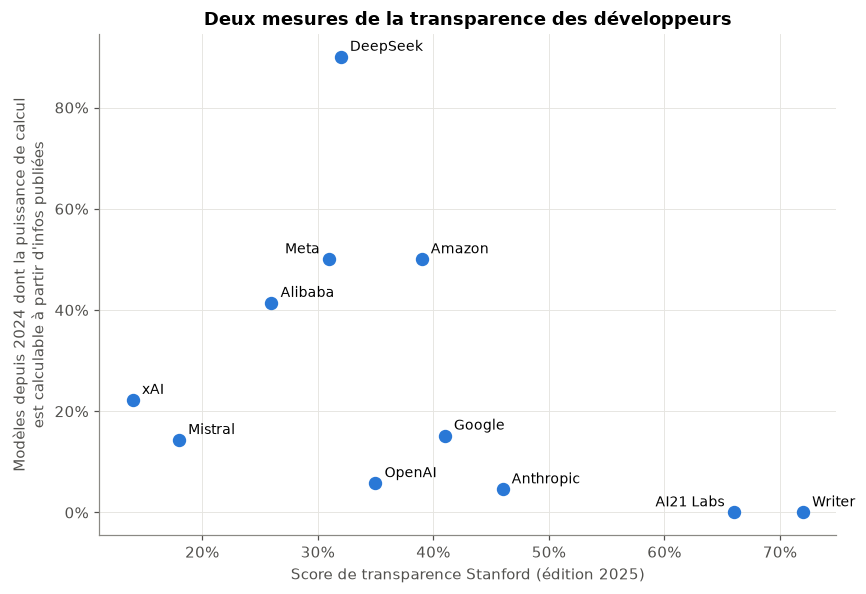

,stanford,modeles,score_epoch,calcul_publie_strict
cle,,,,
Writer,0.72,2,1.00,0.00
AI21 Labs,0.66,1,2.00,0.00
Anthropic,0.46,22,0.14,0.05
Google,0.41,33,0.67,0.15
Amazon,0.39,2,2.50,0.50
OpenAI,0.35,52,0.23,0.06
DeepSeek,0.32,10,3.10,0.90
Meta,0.31,16,2.12,0.50
Alibaba,0.26,29,1.72,0.41


In [13]:
score = analyses.score_stanford(fmti, signataires)
comparaison = analyses.comparer_mesures(score, epoch)
nuage_de_points_annote(comparaison, "stanford", "calcul_publie_strict",
                       "Deux mesures de la transparence des développeurs",
                       "Score de transparence Stanford (édition 2025)",
                       "Modèles depuis 2024 dont la puissance de calcul\nest calculable à partir d'infos publiées",
                       fichier=FIGURES / "rapport_7_deux_mesures.png")
plt.show()
comparaison.round(2)

**Interprétation.** On remarque des résultats assez nuancés et difficiles à interpréter. DeepSeek, Meta et Alibaba ont des modèles bien documentés (on peut calculer la puissance de calcul de 41 % à 90 % de leurs modèles récents), mais Stanford les classe parmi les moins transparents (26 % à 32 %). Anthropic et OpenAI sont dans la situation inverse : 46 % et 35 % chez Stanford, mais presque aucun modèle documenté (5 % et 6 %). Writer et AI21 Labs, en bas à droite, n'ont qu'un ou deux modèles dans Epoch, donc leur position compte peu. Les développeurs de modèles ouverts publient des fiches techniques, mais peu de choses sur leurs données, leurs usages ou leur gouvernance, que Stanford note aussi. H4 ne vaut donc que pour les informations techniques. Mistral, seul développeur français noté, tombe à 18 % chez Stanford en 2025 (55 % en 2024, avec une grille moins exigeante). Ce qui est notable du point de vue français est que Mistral est mal classé par les deux mesures (18 % chez Stanford, 14 % dans Epoch). Le manque de transparence touche donc aussi le seul grand développeur français : la puissance de ses modèles récents est mal connue, ce qui rend la mesure du retard français moins précise (voir 3.6).

### 3.5 L'AI Act a-t-il changé quelque chose ?

On compare les modèles publiés depuis janvier 2024, avant et après le 2 août 2025, selon que le développeur a signé ou non le code de bonnes pratiques. C'est une simple comparaison, elle ne mesure pas un effet de l'AI Act.

In [14]:
analyses.avant_apres_ai_act(epoch, signataires).style.format(
    {"modeles": "{:.0f}", "publie_calcul": "{:.0%}", "publie_donnees": "{:.0%}"})

**Interprétation.** H5 n'est pas confirmée : on n'observe aucune hausse chez les signataires sur cet indicateur. Les signataires (OpenAI, Anthropic, Google, Mistral…) publient beaucoup moins que les autres, avant comme après août 2025 : la puissance de calcul est connue pour 17 % de leurs modèles avant (9 sur 54) et 11 % après (8 sur 70), contre 61 % (59 sur 96) puis 40 % (34 sur 84) pour les non-signataires. Les deux groupes baissent après l'AI Act. On ne peut pas pour autant dire que l'AI Act n'a pas d'effet : il y a encore peu de modèles après août 2025, Epoch met à jour ses fiches avec retard, et les signataires sont surtout de grands laboratoires fermés. De plus, l'AI Act demande un résumé des sources des données d'entraînement, pas leur taille, et ce résumé n'apparaît pas dans Epoch.

### 3.6 Le manque de transparence fausse-t-il la mesure du retard ?

Le retard calculé en 2.4 ne porte que sur les modèles dont la puissance de calcul est connue. Si ce sont surtout les modèles des leaders qui manquent, la comparaison est biaisée. On regarde donc, pour les modèles publiés depuis 2024, la part dont la puissance de calcul est connue, par pays puis pour les quatre grands laboratoires américains.

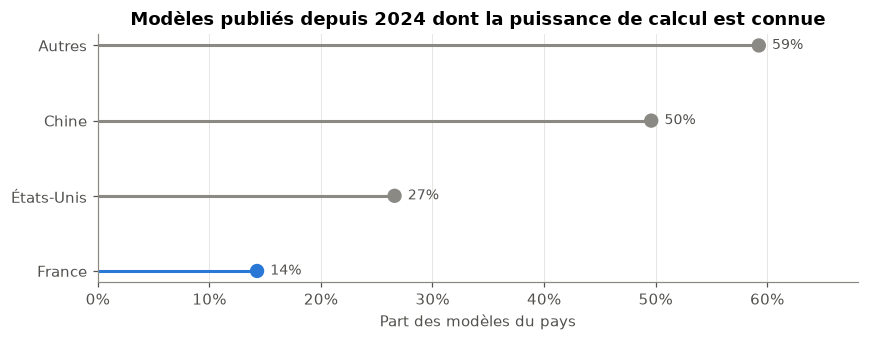

,modeles,part_calcul_connu,part_ouverts
pays,,,
France,7.00,0.14,0.71
États-Unis,179.54,0.27,0.18
Chine,97.58,0.50,0.66
Royaume-Uni,2.25,0.78,0.56
Allemagne,1.00,0.00,0.00
Canada,1.90,0.00,1.00
Autres,23.73,0.59,0.75


,modeles,part_calcul_connu,part_pointe
groupe,,,
"OpenAI, Anthropic, Google DeepMind, xAI",113,0.13,0.12
autres développeurs,200,0.49,0.02


In [15]:
par_pays = analyses.opacite_par_pays(epoch_pays)
# Pays avec au moins 5 modèles récents : en dessous, une part n'a pas de sens
barres_par_pays(par_pays.loc[par_pays["modeles"] >= 5, "part_calcul_connu"],
                "Modèles publiés depuis 2024 dont la puissance de calcul est connue",
                "Part des modèles du pays", fichier=FIGURES / "rapport_6_opacite_pays.png")
plt.show()
display(par_pays.round(2))
analyses.opacite_leaders(epoch).round(2)

**Interprétation.** Depuis 2024, la puissance de calcul est connue pour 27 % des modèles américains et 50 % des modèles chinois. L'écart vient des quatre grands laboratoires (OpenAI, Anthropic, Google DeepMind, xAI) : seulement 13 % de leurs 113 modèles récents, contre 49 % pour les autres développeurs. Or ce sont eux qui font les modèles de pointe (12 % de leurs modèles, contre 2 % pour les autres). Les modèles les plus puissants sont donc ceux qui manquent le plus, et le record américain est probablement sous-estimé. Mais la France suit la même tendance : la puissance de calcul n'est connue que pour 14 % de ses modèles récents, car elle compte peu d'acteurs de premier plan en matière d'IA et ceux-ci sont aussi peu transparents que les grands laboratoires américains. Le record français peut donc être sous-estimé lui aussi. Ces taux ne disent pas ce que valent les modèles manquants : on ne peut pas trancher le sens du biais sur le retard. Le Royaume-Uni, l'Allemagne et le Canada ont moins de cinq modèles récents chacun, donc on ne commente pas leurs chiffres.

## 4. De quoi parle la recherche française en IA ?

**Hypothèse de départ.** Avant de regarder les textes, nous pensions que la recherche française en IA était plus théorique et mathématique (optimisation, statistique) et que la recherche américaine était plus tournée vers les grands modèles, le passage à l'échelle et les agents. On la teste en deux temps : d'abord en comparant les mots (TF-IDF), puis en comparant le sens des résumés (embeddings, section 4.2).

### 4.1 Les mots

On prend les résumés des 1 000 articles d'IA les plus cités depuis 2022 ayant au moins un auteur en France, et la même chose pour les États-Unis. Il faut au moins 35 citations pour entrer dans le classement français, et 319 pour le classement américain. On les nettoie avec spaCy comme dans le cours (lemmatisation, *stopwords*), en retirant aussi les mots qu'on retrouve dans tous les résumés scientifiques. Pour chaque mot, on calcule la part des articles qui le contiennent dans chaque pays. Le rapport entre les deux indique si le mot est plutôt « français » ou plutôt « américain ». Ce rapport est lissé : on ajoute un article fictif de chaque côté, pour éviter une division par zéro quand un mot est absent d'un pays. On ne garde que les mots présents dans au moins 20 articles. Certains articles cosignés par des équipes françaises et américaines apparaissent dans les deux classements : on les retire, sinon ils rapprocheraient artificiellement les deux pays. On retire aussi les textes qui ne sont pas des résumés : pour certains articles de conférence, OpenAlex donne à la place du résumé une notice bibliographique (liste des auteurs, nom de la conférence, année). On les repère parce qu'ils se terminent par une année, comme « Proceedings of the 61st Annual Meeting of the ACL. 2023. ». Dans les nuages de mots, la taille d'un mot correspond à ce rapport.

In [16]:
resumes = corpus_resumes(resumes)     # filtres décrits ci-dessus, dans src/texte.py

nlp = spacy.load("en_core_web_sm")
resumes["tokens"] = nettoyer(resumes["resume"].tolist(), nlp)
comparaison_termes = comparer_presence(resumes.loc[resumes["pays"] == "France", "tokens"].tolist(),
                                       resumes.loc[resumes["pays"] == "États-Unis", "tokens"].tolist())
print(resumes.groupby("pays").size().to_dict())

Articles présents dans les deux corpus, retirés : 18
Notices bibliographiques retirées : {'us': 91, 'fr': 39}


{'France': 832, 'États-Unis': 843}


**TF-IDF.** Comme dans le chapitre « bag of words » du cours, chaque résumé est un document. `TfidfVectorizer` donne à un mot un poids élevé s'il est fréquent dans un résumé mais rare dans l'ensemble des résumés :

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \left(\ln\frac{1 + N}{1 + \text{df}(t)} + 1\right)$$

où $\text{tf}(t, d)$ est le nombre de fois où le mot $t$ apparaît dans le résumé $d$, $N$ le nombre de résumés et $\text{df}(t)$ le nombre de résumés qui contiennent $t$. Les poids de chaque résumé sont ensuite ramenés à une norme 1, pour qu'un résumé long ne pèse pas plus qu'un court. On fait enfin la moyenne par pays.

In [17]:
tfidf = tfidf_par_groupe(resumes["tokens"], resumes["pays"])
pd.DataFrame({p: [f"{t} ({v:.3f})" for t, v in serie.items()] for p, serie in tfidf.items()},
             index=range(1, 16))

,France,États-Unis
1,data (0.036),llm (0.068)
2,learning (0.029),language (0.043)
3,base (0.025),data (0.035)
4,language (0.023),prompt (0.029)
5,algorithm (0.022),human (0.027)
6,dataset (0.022),learning (0.027)
7,network (0.022),training (0.026)
8,system (0.021),reasoning (0.026)
9,detection (0.020),agent (0.022)
10,speech (0.019),text (0.022)


**Interprétation.** Les premiers mots sont en partie les mêmes dans les deux pays (*data*, *learning*, *language*, *dataset*) : c'est le vocabulaire de base de l'IA. Mais aux États-Unis, *llm*, *prompt*, *reasoning* et *agent* sont dans le top 10, alors qu'en France on y trouve *speech* et *detection*, et *llm* n'apparaît même pas dans les 15 premiers.

**Les mots propres à chaque pays.** Le TF-IDF fait surtout ressortir des mots communs aux deux corpus. Pour voir ce qui distingue chaque pays, on compare directement la part des articles qui contiennent chaque mot.

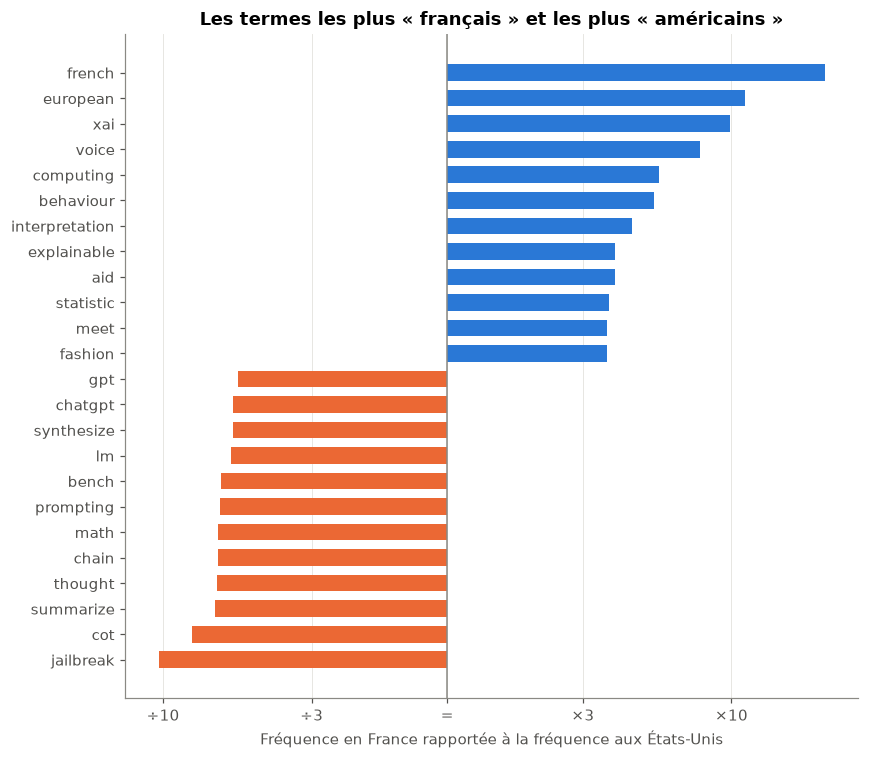

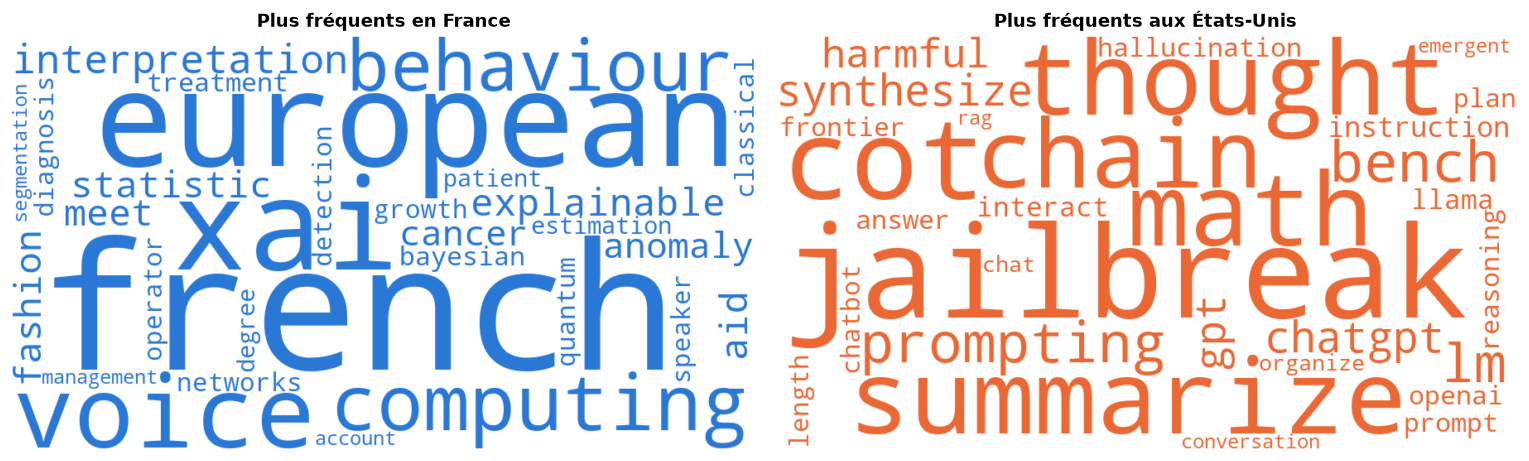

In [18]:
extremes = pd.concat([comparaison_termes.head(12), comparaison_termes.tail(12)])
barres_rapport(extremes, "Les termes les plus « français » et les plus « américains »",
               fichier=FIGURES / "rapport_4_termes.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cote_fr = comparaison_termes.head(30)
cote_us = comparaison_termes.tail(30)
nuage(dict(zip(cote_fr["terme"], cote_fr["rapport"])), axes[0], "Plus fréquents en France", COULEURS_PAYS["France"])
nuage(dict(zip(cote_us["terme"], 1 / cote_us["rapport"])), axes[1], "Plus fréquents aux États-Unis", COULEURS_PAYS["États-Unis"])
fig.tight_layout(); fig.savefig(FIGURES / "rapport_5_nuages.png"); plt.show()

**Interprétation.** H6 est confirmée. Les articles français parlent beaucoup plus d'IA explicable : *xai* apparaît dans 38 articles français contre 3 américains (rapport lissé de 9,9), *explainable* et *interpretation* environ 4 fois plus. On y trouve aussi la voix (*voice*), la détection d'anomalies, la statistique (*statistic*) et des mots liés à l'Europe (*european*, *french*). Les articles américains parlent surtout des grands modèles de langage : *chatgpt*, *gpt*, *instruction*, *prompting*, le raisonnement étape par étape (*chain*, *thought*, *cot*) et le contournement des protections (*jailbreak*), 5 à 10 fois plus fréquents qu'en France. Les termes *theoretical* et *statistic* sont aussi 2 à 4 fois plus fréquents en France, alors que *agent* et *scale* sont environ 1,7 fois plus fréquents aux États-Unis (détail dans l'annexe 02). Cela rejoint la partie 2 : la France publie, mais peu sur les sujets où se joue la course aux modèles. Limite : les articles français sont beaucoup moins cités que les américains (médiane de 62 citations contre 509).

### 4.2 Le sens : les embeddings

Le TF-IDF compare des mots : deux résumés qui parlent du même sujet avec des mots différents (*LLM* et *large language model*) y sont éloignés. Un modèle d'**embedding** transforme chaque résumé en un vecteur de 1 024 nombres, construit pour que deux textes de sens proche aient des vecteurs proches. On mesure la proximité de deux résumés par le cosinus de l'angle entre leurs vecteurs $a$ et $b$ :

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

Il vaut 1 si les deux vecteurs pointent dans la même direction et 0 s'ils sont perpendiculaires. Nos vecteurs sont de norme 1 : le cosinus est donc simplement leur produit scalaire $a \cdot b$.

Nous utilisons `harrier-oss-v1-0.6b` (Microsoft, licence MIT), un modèle multilingue que nous faisons tourner en local avec la bibliothèque `sentence-transformers` (voir `src/embeddings.py`). Le calcul prend environ six minutes sur un ordinateur portable : il est fait une seule fois et les vecteurs sont enregistrés dans `data/processed/`. Le rapport relit ce fichier, il n'a donc besoin ni du modèle ni de `torch`. Mettre `RECALCULER_EMBEDDINGS = True` relance le calcul.

In [19]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import embeddings
from graphiques import figure_reduction, nuage_pays, carte_groupes, barres_part_france, histogramme_scores, halteres_groupes, barres_ecarts

RECALCULER_EMBEDDINGS = False
if RECALCULER_EMBEDDINGS or not (embeddings.FICHIER_RESUMES.exists() and embeddings.FICHIER_REFERENCES.exists()):
    embeddings.calculer(charger_dernier("openalex_resumes"))

vecteurs = embeddings.charger(resumes["id"])
print(f"{vecteurs.shape[0]} résumés × {vecteurs.shape[1]} dimensions")

1675 résumés × 1024 dimensions


**Une carte des articles : ACP puis t-SNE.** On ne peut pas dessiner 1 024 dimensions : il faut résumer chaque article par 2 nombres. On le fait en deux étapes.

- L'**ACP** (analyse en composantes principales) cherche les directions dans lesquelles les vecteurs varient le plus et ne garde que les premières. Ici aucune direction ne domine : le sens d'un texte est réparti sur beaucoup de directions, et les 2 premières composantes gardent très peu de variance (figure de gauche). Une carte faite avec l'ACP seule sépare déjà en partie les deux pays le long de la première composante, mais elle ne garde presque aucun voisinage : on n'y distingue pas les thèmes (figure du milieu). On garde 50 composantes, ce qui retire les directions les moins informatives et allège le calcul suivant.
- Le **t-SNE** part de ces 50 coordonnées et place les articles sur un plan en cherchant à ce que chaque article garde les mêmes voisins. Il préserve les voisinages, pas les grandes distances.

Pour vérifier que la réduction est fidèle, on compte, pour chaque article, combien de ses 10 plus proches voisins dans l'espace de départ se retrouvent parmi ses 10 plus proches voisins après réduction (figure de droite).

Trois précautions de lecture. Les axes de la carte n'ont pas de sens en eux-mêmes. Seuls les voisinages se lisent : deux points proches ont des résumés proches, mais la distance entre deux amas éloignés n'a pas de signification précise. Enfin, la carte ne sert qu'à voir : les groupes et les scores des sections suivantes sont calculés sur les vecteurs d'origine, pas sur la carte.

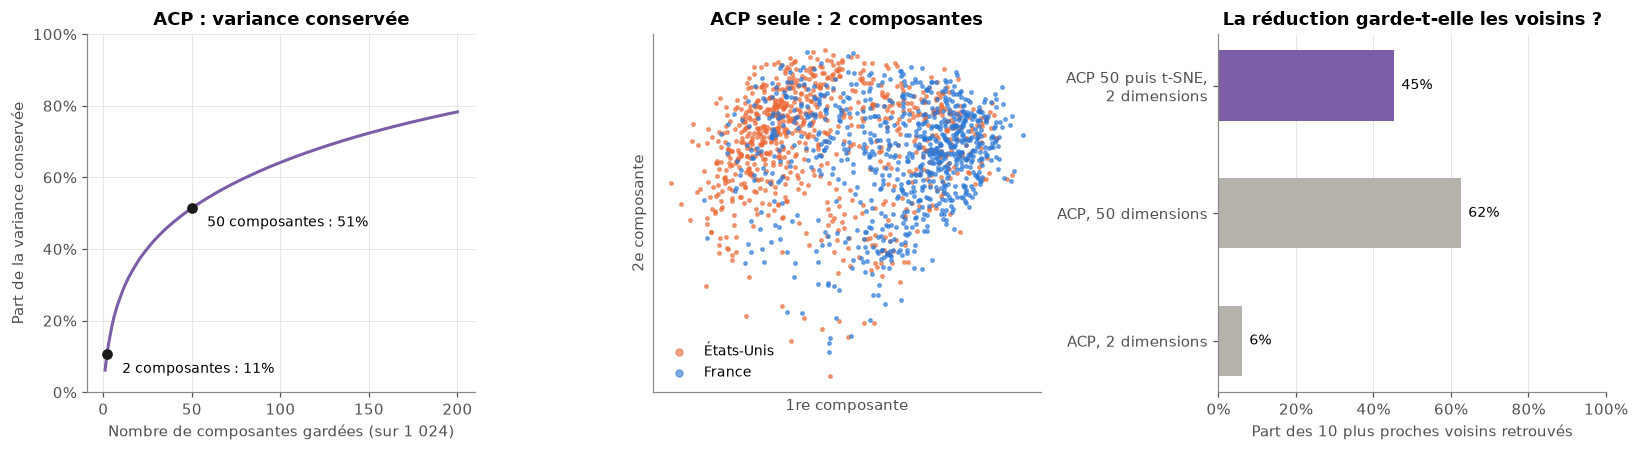

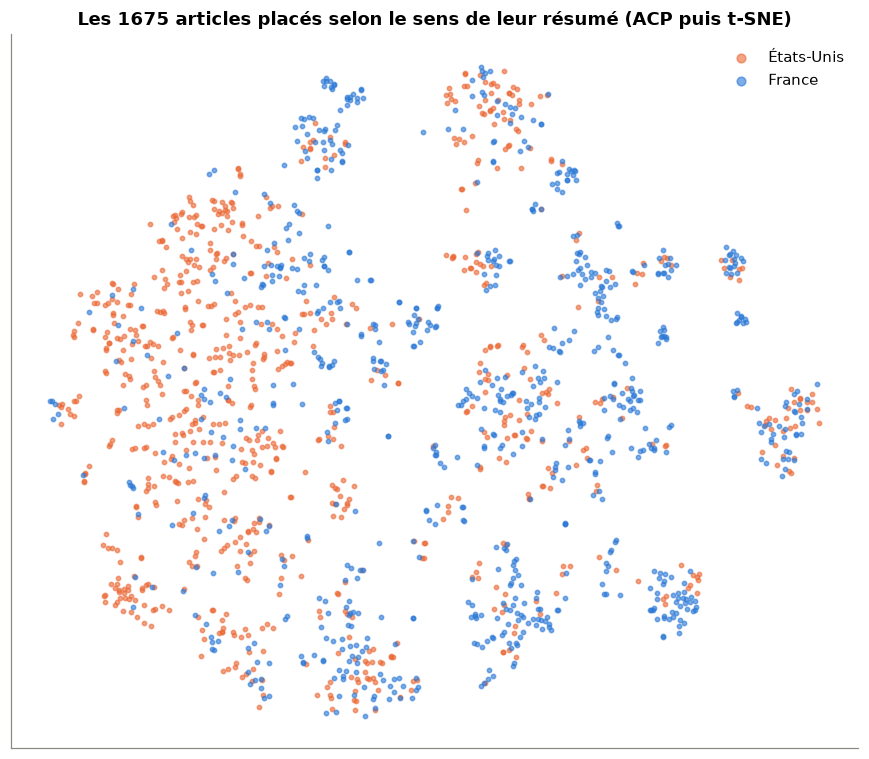

In [20]:
acp50 = PCA(n_components=50, random_state=0).fit_transform(vecteurs)
plan = TSNE(n_components=2, random_state=0, init="pca").fit_transform(acp50)
resumes[["x", "y"]] = plan

# Les deux étapes : variance gardée par l'ACP, carte avec l'ACP seule, voisins retrouvés
variance_gardee = PCA(random_state=0).fit(vecteurs).explained_variance_ratio_.cumsum()
fidelite = pd.Series({"ACP, 2 dimensions": embeddings.voisins_retrouves(acp50[:, :2], vecteurs),
                      "ACP, 50 dimensions": embeddings.voisins_retrouves(acp50, vecteurs),
                      "ACP 50 puis t-SNE,\n2 dimensions": embeddings.voisins_retrouves(plan, vecteurs)})
figure_reduction(variance_gardee, acp50[:, :2], resumes["pays"], fidelite,
                 fichier=FIGURES / "rapport_6a_acp_tsne.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
nuage_pays(ax, resumes["x"], resumes["y"], resumes["pays"],
           f"Les {len(resumes)} articles placés selon le sens de leur résumé (ACP puis t-SNE)")
ax.legend(markerscale=2)
fig.tight_layout(); fig.savefig(FIGURES / "rapport_6_carte_embeddings.png"); plt.show()

**Interprétation.** L'ACP confirme qu'aucune direction ne domine : les 2 premières composantes ne gardent que 11 % de la variance, les 50 premières 51 %. Avec l'ACP seule, on ne retrouve que 6 % des 10 plus proches voisins de chaque article, contre 45 % sur la carte t-SNE (et 62 % avec l'ACP à 50 dimensions, qu'on ne peut pas dessiner). La carte t-SNE déforme donc l'espace de départ, mais elle est bien plus fidèle qu'une ACP à 2 dimensions.

Sur cette carte, les articles français et américains n'occupent pas les mêmes zones. Les articles américains forment une grande masse sur la moitié gauche, alors que les articles français dominent plusieurs amas plus petits au centre et à droite. Les frontières entre les zones restent floues : les deux pays travaillent en partie sur les mêmes sujets, mais leurs centres de gravité sont différents. La carte ne fait que montrer ces différences, les sections suivantes les mesurent.

**Des thèmes trouvés sans mots-clés.** On regroupe les articles en 8 groupes par la méthode des k-moyennes appliquée aux vecteurs. Pour nommer chaque groupe, on réutilise le TF-IDF de la section 4.1 : ses mots les plus caractéristiques. Les deux méthodes se complètent : les embeddings forment les groupes, le TF-IDF les rend lisibles.

In [21]:
resumes["groupe"] = KMeans(n_clusters=8, random_state=0, n_init=10).fit_predict(vecteurs)
mots_groupes = tfidf_par_groupe(resumes["tokens"], resumes["groupe"], n=6)

groupes = (resumes.groupby("groupe")
           .agg(articles=("id", "size"),
                part_france=("pays", lambda p: (p == "France").mean()))
           .assign(mots=lambda t: [", ".join(mots_groupes[g].index) for g in t.index])
           .sort_values("part_france", ascending=False))
print(f"Part de la France dans tout le corpus : {(resumes['pays'] == 'France').mean():.0%}")
groupes.round(2)

Part de la France dans tout le corpus : 50%


,articles,part_france,mots
groupe,,,
5,162,0.78,"algorithm, graph, quantum, network, function, ..."
0,168,0.70,"attack, privacy, data, learning, client, anomaly"
4,250,0.66,"image, data, learning, feature, label, cancer"
1,219,0.65,"explanation, system, xai, intelligence, artifi..."
3,327,0.46,"language, text, speech, llm, data, training"
6,100,0.44,"llm, chatgpt, application, data, research, lan..."
7,89,0.38,"robot, policy, agent, navigation, learning, ac..."
2,360,0.14,"llm, language, reasoning, prompt, human, agent"


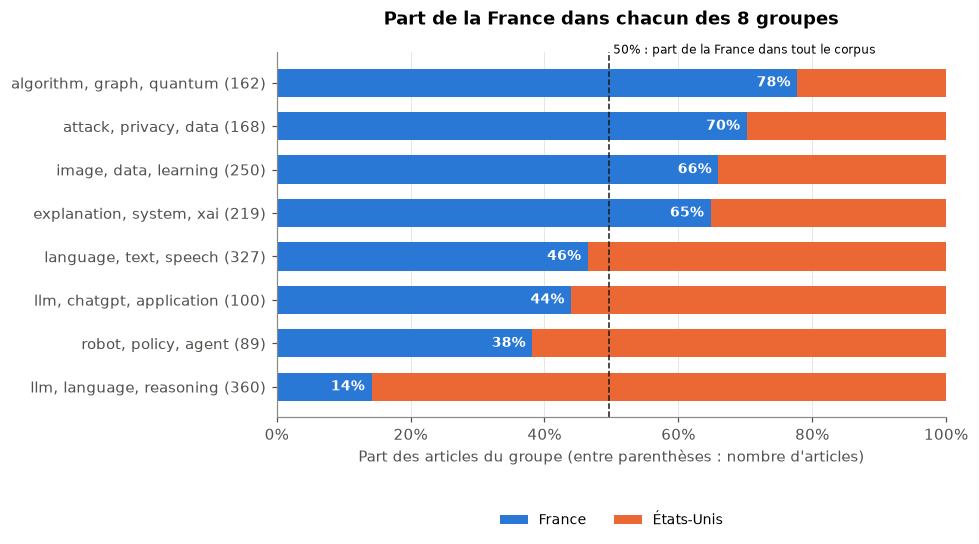

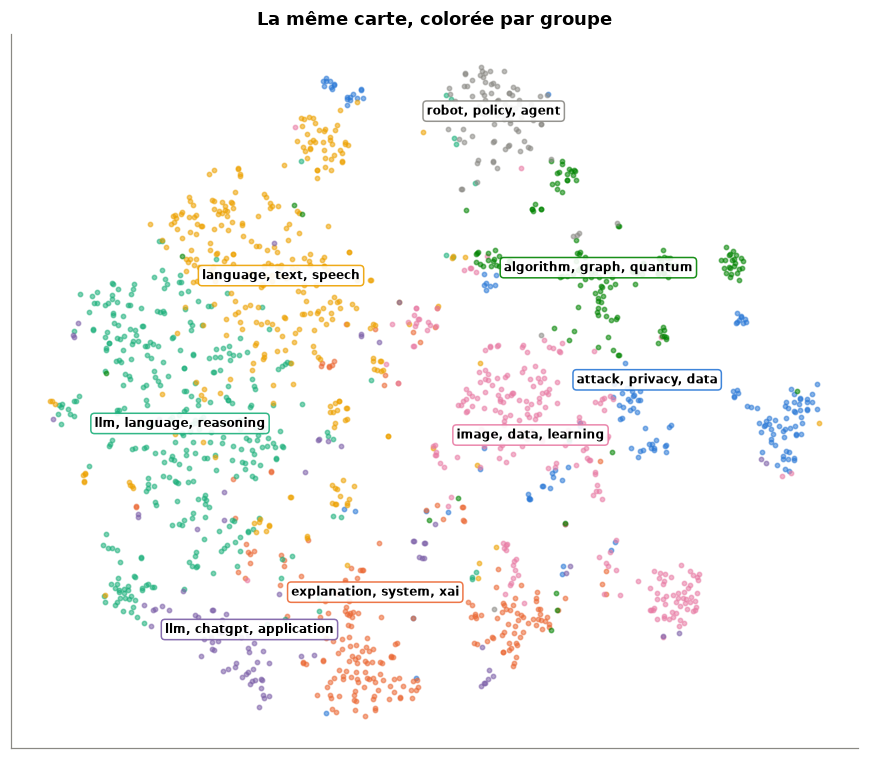

In [22]:
# Chaque groupe est désigné par ses 3 mots les plus caractéristiques (TF-IDF)
etiquettes = {g: ", ".join(mots_groupes[g].index[:3]) for g in groupes.index}
barres_part_france(groupes, etiquettes, (resumes["pays"] == "France").mean(),
                   "Part de la France dans chacun des 8 groupes",
                   fichier=FIGURES / "rapport_6b_part_france_groupes.png")
plt.show()
carte_groupes(resumes, etiquettes, "La même carte, colorée par groupe",
              fichier=FIGURES / "rapport_6c_carte_groupes.png")
plt.show()

**Interprétation.** La France représente la moitié du corpus, mais sa part varie beaucoup d'un groupe à l'autre. Elle est nettement majoritaire dans quatre groupes : les algorithmes et la théorie (78 %), la sécurité et la vie privée (70 %), l'image (66 %) et l'IA explicable (65 %). Elle représente un peu moins de la moitié du groupe sur la langue et la parole (46 %). À l'inverse, le groupe le plus nombreux, celui des grands modèles de langage, du raisonnement et des agents (360 articles), n'est français qu'à 14 %. Sur la carte colorée par groupe, la grande zone américaine de gauche correspond au groupe *llm, language, reasoning*, et les amas où les articles français dominent aux groupes *algorithm, graph, quantum*, *attack, privacy, data* et *image, data, learning*. Ces groupes ont été formés à partir du sens des résumés, sans liste de mots fixée à l'avance, et ils retrouvent pourtant les oppositions de la section 4.1.

**Les deux méthodes trouvent-elles les mêmes groupes ?** Pour mesurer l'accord entre le TF-IDF et les embeddings, on refait 8 groupes avec les k-moyennes, cette fois sur les vecteurs TF-IDF de la section 4.1, puis on compare les deux découpages avec l'**indice de Rand ajusté**. Il compte les paires d'articles que les deux méthodes mettent ensemble ou séparent de la même façon, corrigé du hasard : il vaut 1 si les groupes sont identiques et 0 si l'accord n'est pas meilleur que le hasard. Le tableau croise les deux découpages.

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score

# Mêmes réglages que la section 4.1 (TF-IDF) et que les groupes ci-dessus (8 groupes, même graine)
matrice_tfidf = TfidfVectorizer(min_df=5).fit_transform(resumes["tokens"].str.join(" "))
resumes["groupe_tfidf"] = KMeans(n_clusters=8, random_state=0, n_init=10).fit_predict(matrice_tfidf)

# Indice de Rand ajusté : 1 = mêmes groupes, 0 = pas plus d'accord que le hasard
ari = adjusted_rand_score(resumes["groupe"], resumes["groupe_tfidf"])
print(f"Indice de Rand ajusté entre les groupes TF-IDF et les groupes embeddings : {ari:.2f}")
pd.crosstab(resumes["groupe"], resumes["groupe_tfidf"], rownames=["embeddings"], colnames=["TF-IDF"])

Indice de Rand ajusté entre les groupes TF-IDF et les groupes embeddings : 0.25


TF-IDF,0,1,2,3,4,5,6,7
embeddings,,,,,,,,
0,1,11,0,1,7,26,43,79
1,127,6,2,4,1,0,10,69
2,14,83,170,52,4,32,3,2
3,4,218,53,3,5,2,30,12
4,0,57,0,0,6,5,113,69
5,2,0,0,0,19,0,126,15
6,30,9,30,3,1,5,8,14
7,1,4,1,56,1,0,16,10


**Interprétation.** L'indice vaut 0,25 : les deux méthodes s'accordent nettement plus que le hasard, mais elles sont loin de produire les mêmes groupes. Le tableau montre que les thèmes les plus nets se retrouvent des deux côtés : la majorité des articles sur l'IA explicable (127 sur 219), la langue et la parole (218 sur 327) et les algorithmes (126 sur 162) tombent dans un même groupe TF-IDF. Pour les grands modèles de langage, c'est un peu moins de la moitié (170 sur 360). Les désaccords portent surtout sur les autres groupes, dont les articles se répartissent entre plusieurs groupes TF-IDF. Les grands thèmes qui opposent la France et les États-Unis se retrouvent donc en partie avec les deux méthodes, mais l'accord reste partiel et les frontières entre groupes ne doivent pas être lues comme nettes.

**Théorique ou appliquée ?** Pour tester directement l'hypothèse de départ, on écrit huit phrases de référence : quatre décrivent un article théorique (« We prove a theorem and derive convergence guarantees… »), quatre un article appliqué (« We deploy the system in a real-world application… »). Pour chaque résumé $r$, le score est sa proximité moyenne aux quatre phrases théoriques $t_i$ moins sa proximité moyenne aux quatre phrases appliquées $p_i$ :

$$\text{score}(r) = \frac{1}{4}\sum_{i=1}^{4} \cos(r, t_i) - \frac{1}{4}\sum_{i=1}^{4} \cos(r, p_i)$$

 Un score plus élevé veut dire un résumé plus proche du type « théorique ». Les phrases sont dans `src/embeddings.py`. C'est une mesure construite par nous : on vérifie à la main qu'elle classe bien les articles en lisant les titres des extrêmes.

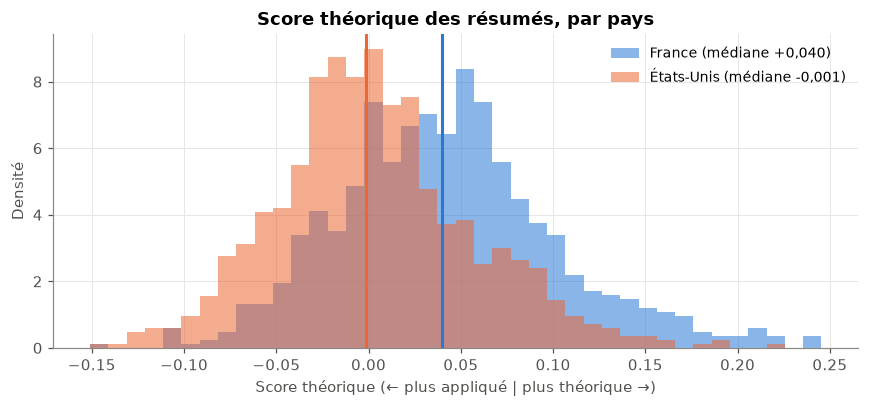

Médiane France : 0.040, États-Unis : -0.001
Test de Mann-Whitney : p = 2.6e-42
Part des paires (résumé français, résumé américain) où le français a le score le plus élevé : 69%


In [24]:
resumes["score_theorique"] = embeddings.score_theorique(vecteurs, embeddings.charger_references())

histogramme_scores(resumes, "score_theorique", "Score théorique des résumés, par pays",
                   "Score théorique (← plus appliqué | plus théorique →)",
                   fichier=FIGURES / "rapport_7_score_theorique.png")
plt.show()

from scipy.stats import mannwhitneyu
fr = resumes.loc[resumes["pays"] == "France", "score_theorique"]
us = resumes.loc[resumes["pays"] == "États-Unis", "score_theorique"]
print(f"Médiane France : {fr.median():.3f}, États-Unis : {us.median():.3f}")
test = mannwhitneyu(fr, us)
print(f"Test de Mann-Whitney : p = {test.pvalue:.2g}")
print(f"Part des paires (résumé français, résumé américain) où le français a le score le plus élevé : {test.statistic / (len(fr) * len(us)):.0%}")

In [25]:
# Vérification à la main : les titres les plus « théoriques » et les plus « appliqués »
extremes_score = resumes.sort_values("score_theorique")
pd.concat({"plus appliqués": extremes_score.head(5), "plus théoriques": extremes_score.tail(5)})[["titre", "pays", "score_theorique"]]

titre  \
plus appliqués  975   Evaluating local open-source large language mo...   
                1443  Prometheus: Inducing Fine-grained Evaluation C...   
                1396  Improving large language models for clinical n...   
                1406  Creating Large Language Model Applications Uti...   
                1882  Multi-model assurance analysis showing large l...   
plus théoriques 338   Rigorous Dynamical Mean-Field Theory for Stoch...   
                238   Compressed and distributed least-squares regre...   
                324   Sharp optimal recovery in the two component Ga...   
                546   Finite-Time High-Probability Bounds for Polyak...   
                59    Handbook of Convergence Theorems for (Stochast...   

                            pays  score_theorique  
plus appliqués  975       France            -0.15  
                1443  États-Unis            -0.15  
                1396  États-Unis            -0.14  
                1406  États-Unis            -0.13  
                1882  États-Unis            -0.13  
plus théoriques 338       France             0.22  
                238       France             0.22  
                324       France             0.24  
                546       France             0.24  
                59        France             0.25

**Le score dépend-il des phrases choisies ?** Le score repose sur huit phrases écrites par nous. Pour vérifier qu'aucune ne fabrique le résultat à elle seule, on retire chaque phrase à son tour et on recalcule l'écart des médianes entre la France et les États-Unis. La quatrième phrase « appliquée » mérite une attention particulière : elle décrit le réglage fin d'un grand modèle de langage, un thème dont on a vu qu'il est surtout américain.

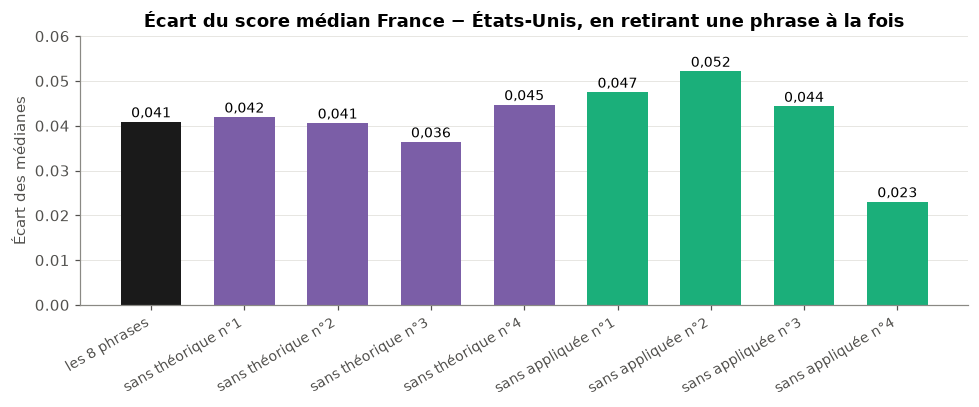

Test de Mann-Whitney sans la phrase sur les grands modèles de langage : p = 3e-27


In [26]:
references = embeddings.charger_references()
est_francais = (resumes["pays"] == "France").to_numpy()
ecarts = embeddings.ecarts_sans_une_phrase(vecteurs, references, est_francais)
barres_ecarts(ecarts, "Écart du score médian France − États-Unis, en retirant une phrase à la fois",
              "Écart des médianes", fichier=FIGURES / "rapport_7b_sensibilite.png")
plt.show()

sans_llm = references.loc[~references["phrase"].str.contains("large language model")]
score_sans_llm = embeddings.score_theorique(vecteurs, sans_llm)
test_sans_llm = mannwhitneyu(score_sans_llm[est_francais], score_sans_llm[~est_francais])
print(f"Test de Mann-Whitney sans la phrase sur les grands modèles de langage : p = {test_sans_llm.pvalue:.2g}")

**À sujet égal ?** Une partie de l'écart peut venir de la composition des corpus : si les articles américains portent plus souvent sur les grands modèles de langage, sujet plutôt appliqué, le score moyen des États-Unis baisse même si, à sujet égal, les deux pays écrivent pareil. On compare donc les scores des deux pays à l'intérieur de chaque groupe de la section précédente.

Écart des médianes sur tout le corpus : 0.041
Écart médian à l'intérieur des groupes : 0.010


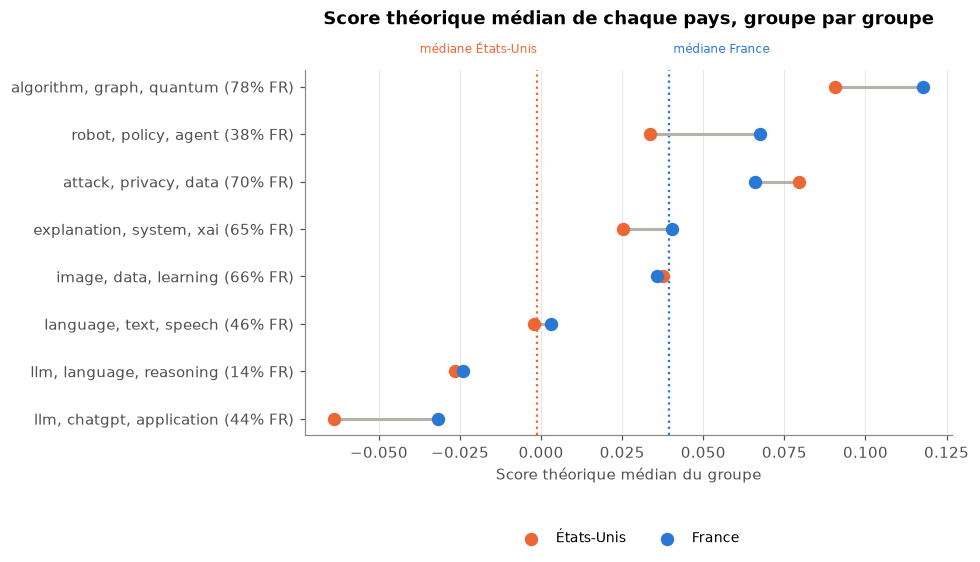

,France,États-Unis,ecart,articles,part_france,mots
groupe,,,,,,
5,0.118,0.091,0.027,162,0.778,"algorithm, graph, quantum, network, function, ..."
7,0.067,0.034,0.034,89,0.382,"robot, policy, agent, navigation, learning, ac..."
0,0.066,0.080,-0.014,168,0.702,"attack, privacy, data, learning, client, anomaly"
1,0.040,0.025,0.015,219,0.648,"explanation, system, xai, intelligence, artifi..."
4,0.036,0.038,-0.002,250,0.660,"image, data, learning, feature, label, cancer"
3,0.003,-0.002,0.005,327,0.465,"language, text, speech, llm, data, training"
2,-0.024,-0.027,0.003,360,0.142,"llm, language, reasoning, prompt, human, agent"
6,-0.032,-0.064,0.032,100,0.440,"llm, chatgpt, application, data, research, lan..."


In [27]:
par_groupe = (resumes.groupby(["groupe", "pays"])["score_theorique"].median().unstack("pays")
              .assign(ecart=lambda t: t["France"] - t["États-Unis"]))
par_groupe = par_groupe.join(groupes[["articles", "part_france", "mots"]]).sort_values("France", ascending=False)
print(f"Écart des médianes sur tout le corpus : {fr.median() - us.median():.3f}")
print(f"Écart médian à l'intérieur des groupes : {par_groupe['ecart'].median():.3f}")
halteres_groupes(par_groupe, etiquettes, fr.median(), us.median(),
                 "Score théorique médian de chaque pays, groupe par groupe", "Score théorique médian du groupe",
                 fichier=FIGURES / "rapport_7c_score_par_groupe.png")
plt.show()
with pd.option_context("display.float_format", "{:.3f}".format):
    display(par_groupe)

**Interprétation.** Les résumés français sont plus proches des phrases « théoriques » que les résumés américains (score médian de 0,040 contre −0,001). Le test de Mann-Whitney rejette l'égalité des deux distributions, et dans 69 % des paires formées d'un résumé français et d'un résumé américain, c'est le français qui a le score le plus élevé. Les cinq articles les plus théoriques sont français et portent sur des preuves de convergence ou des bornes statistiques : les extrêmes du classement sont plausibles, même si cela ne valide pas le score pour chacun des 1 675 articles.

Le score dépend des phrases choisies, mais aucune ne fabrique le résultat à elle seule : l'écart reste positif dans les neuf cas, de 0,023 à 0,052. La phrase la plus influente est celle sur les grands modèles de langage : sans elle, l'écart passe de 0,041 à 0,023. Il reste significatif, mais il est presque divisé par deux. Une partie de l'écart vient donc du thème des articles plutôt que de leur caractère théorique. H6 est confirmée sur ce corpus, avec cette réserve.

À l'intérieur de chaque groupe, l'écart entre les deux pays est en général plus faible que sur tout le corpus : il va de −0,014 à 0,034 selon les groupes, avec une médiane de 0,010, contre 0,041 sur l'ensemble. Cela suggère un effet de composition : les chercheurs français choisissent plus souvent des sujets théoriques et travaillent moins sur les grands modèles de langage. Ce n'est pas une décomposition exacte de l'écart, car les huit groupes n'ont pas la même taille.

**Limites des embeddings.** Le modèle a été entraîné par Microsoft sur des données que nous ne connaissons pas, et la carte t-SNE dépend de ses réglages. Le score théorique dépend des huit phrases choisies : changer les phrases change les scores, c'est pourquoi on ne compare que les deux pays entre eux, avec les mêmes phrases.

## Conclusion

La France est bien en retard, et rien n'indique que ce soit un effet de la transparence. Elle publie presque autant de recherche en IA par habitant que les États-Unis, mais n'a produit aucun modèle de pointe en 2024-2025. Sa présence repose sur Mistral AI et sur des collaborations, et elle a entre 1 et 4 ans de retard sur les États-Unis en puissance de calcul depuis 2018 (3 ans en 2026).

Les développeurs publient bien de moins en moins : la part des modèles dont la puissance de calcul est connue a été divisée par trois depuis 2021. Ce sont surtout les grands laboratoires américains qui ne publient pas (13 % de modèles documentés, contre 49 % pour les autres développeurs), mais les modèles français récents sont aussi peu documentés (14 %) : le retard de trois ans est un écart entre records documentés, et le sens du biais reste incertain. Enfin, la transparence est difficile à mesurer : les modèles ouverts sont bien documentés techniquement mais pas sur leurs données et leurs usages, et on n'observe pas encore de hausse de la transparence chez les signataires du code de l'AI Act.

Par ailleurs, l'analyse des résumés d'articles montre que la recherche française en IA ne porte pas sur les mêmes sujets que la recherche américaine. Dans les 1 675 résumés étudiés, elle est plus tournée vers la théorie et l'explicabilité des modèles, alors que la recherche américaine se concentre sur les grands modèles de langage. C'est une explication possible, que nos données ne permettent pas de tester, du fait que la France publie beaucoup mais produit peu de modèles : ses chercheurs travaillent moins sur le domaine où se joue la course. Les embeddings des résumés le confirment et le précisent : l'écart entre les deux pays tient en partie au choix des sujets, la France représentant entre 65 % et 78 % des articles sur les algorithmes, la sécurité, l'image ou l'explicabilité, mais seulement 14 % de ceux sur les grands modèles de langage.

**Limites.** Epoch ne retient que les modèles « notables » et mesure ce qui est connu, pas forcément ce qui est publié par le développeur. OpenAlex donne le pays d'affiliation des auteurs, pas leur nationalité. Pour l'analyse des textes, nous n'avons étudié que les articles les plus cités, et les articles français retenus sont beaucoup moins cités que les américains. Enfin, on a un peu plus d'un an de recul sur l'AI Act.

**Pour aller plus loin**, on pourrait suivre les résumés de données d'entraînement publiés au titre de l'AI Act, élargir la comparaison au reste de l'Europe, ou étudier le départ des chercheurs français vers les entreprises américaines.